In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import xarray as xr
import harmonica as hm
import verde as vd
import pygmt
import pyproj

In [2]:
#Primeiro importamos os dados que baixamos no site do ICGEM
GD_sa_GOCO06s = hm.load_icgem_gdf(
    fname="../dados/gravity_disturbance_sa_GOCO06s_2221b8a5386c5dafee229415711f87ae486abb80ab756e6ca765403e6b22a4a1.gdf"
)
GD_sa_GOCO06s

<xarray.Dataset> Size: 17MB
Dimensions:                 (latitude: 301, longitude: 3601)
Coordinates:
  * latitude                (latitude) float64 2kB -90.0 -89.9 ... -60.1 -60.0
  * longitude               (longitude) float64 29kB -180.0 -179.9 ... 180.0
Data variables:
    gravity_disturbance_sa  (latitude, longitude) float64 9MB -22.72 ... -32.5
    height_over_ell         (latitude, longitude) float64 9MB 5e+03 ... 5e+03
Attributes: (12/34)
    generating_institute:  gfz-potsdam
    generating_date:       2026/09/29
    product_type:          gravity_field
    body:                  earth
    modelname:             goco06s
    max_used_degree:       300
    ...                    ...
    maxvalue:              1.1654890E+02 mgal
    minvalue:              -1.3763173E+02 mgal
    signal_wrms:           3.1295291E+01 mgal
    grid_format:           long_lat_value
    attributes:            longitude latitude gravity_disturbance_sa
    attributes_units:      deg. deg. mgal

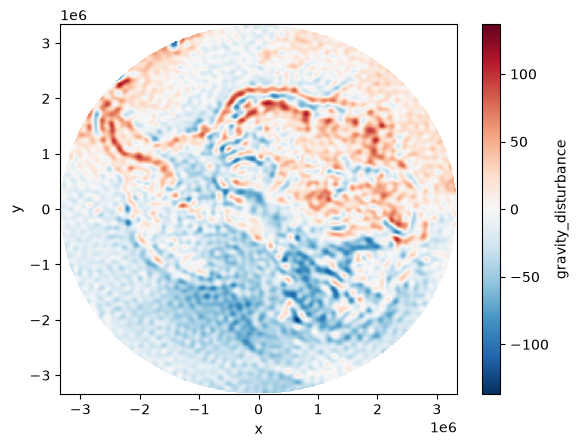

In [3]:
projection = pyproj.Proj('epsg:3031')
polar_data = vd.project_grid(
    GD_sa_GOCO06s.gravity_disturbance_sa, projection, spacing=11e3, dims=("y", "x")

)
polar_data = polar_data.to_dataset(name = "gravity_disturbance")
polar_data.gravity_disturbance.plot()

In [4]:
data_set = xr.load_dataset("../dados/BedMachineAntarctica_v3.nc")
data_set

<xarray.Dataset> Size: 4GB
Dimensions:    (y: 13333, x: 13333)
Coordinates:
  * y          (y) int32 53kB 3333000 3332500 3332000 ... -3332500 -3333000
  * x          (x) int32 53kB -3333000 -3332500 -3332000 ... 3332500 3333000
Data variables:
    mapping    |S1 1B b''
    mask       (y, x) int8 178MB 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0
    firn       (y, x) float32 711MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    surface    (y, x) float32 711MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    thickness  (y, x) float32 711MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    bed        (y, x) float32 711MB -5.916e+03 -5.92e+03 ... -3.664e+03
    errbed     (y, x) float32 711MB nan nan nan nan nan ... nan nan nan nan nan
    source     (y, x) int8 178MB 1 1 1 1 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1 1 1 1 1
    dataid     (y, x) int8 178MB 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0
    geoid      (y, x) int16 356MB -1 -1 -1 -1 -1 -1 ... -19 -19 -19 -19 -19 -19
Attributes: (12/17)
    Conventions:                 CF-1.7
    Title:                       BedMachine Antarctica
    Author:                      Mathieu Morlighem
    version:                     03-Jun-2022 (v3.4)
    nx:                          13333.0
    ny:                          13333.0
    ...                          ...
    ymax:                        3333000
    spacing:                     500
    no_data:                     -9999.0
    license:                     No restrictions on access or use
    Data_citation:               Morlighem M. et al., (2019), Deep glacial tr...
    Notes:                       Data processed at the Department of Earth Sy...

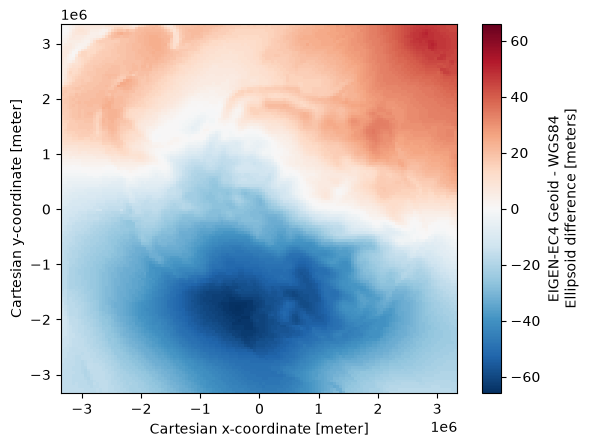

In [ ]:
# Vamos plotar o geoide 
data_set.geoid[::100, ::100].plot()

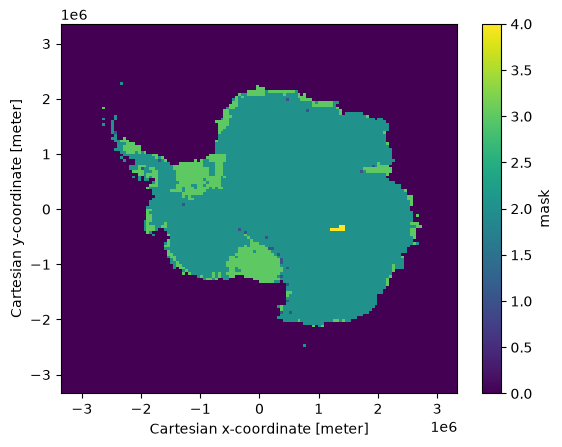

In [ ]:
# Mascara dos dados relacionados as regiões onde tem certas coisas kkkk
data_set.mask[::100, ::100].plot()

In [9]:
data_set['bed_ell'] = data_set.bed + data_set.geoid
data_set['ice_surface'] = data_set.surface + data_set.geoid
data_set['ice_base'] = data_set.surface - data_set.thickness